# Step 2. Do the detectors work on real exams?

**The question.** Step 1 trained two detectors that score well on their own test split. The product, though,
reads exams it has never seen: the 50 handwritten exams of the Mendeley dataset (Data Science exam answer
sheets, with the teacher's marks and an answer key; step 7 describes them). This chapter records the first time
the whole reader met those exams, what went wrong, and the two decisions that shaped everything after it.

This chapter **does not read any exam again**. It loads the results saved when these tries were made
(`artifacts/vision/step2_first_reader/`) and the log of every try (`artifacts/vision/tries.csv`).

    Part 1  The first reader      rules and detectors on all 50 exams: the detectors do not transfer
    Part 2  Where to get data     a search for public handwritten question numbers: none usable
    Part 3  A mistake, corrected  tries 6 to 8 tuned the reader on Mendeley exams; they are superseded
    Part 4  Two decisions         Mendeley is evaluation-only, and a development set is built (step 3)

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vision" / "reader.py").is_file())
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from vision import datasets, eda  # noqa: E402

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 120)
OUT = datasets.ARTIFACTS / "step2_first_reader"
tries = pd.read_csv(datasets.ARTIFACTS / "tries.csv")

## Part 1. The first reader on the 50 Mendeley exams

Reader v1 had two modes. **detectors**: the two YOLO models of step 1 find the question numbers and the lines,
and TrOCR base reads them. **rules**: the no-learning baselines find them instead. Each answer is put under the
question number found on its line, and matched to the answer key by that number. This run was made once, on all
50 exams, before any choice was based on them, so it is a clean result.

In [2]:
v1 = pd.read_csv(OUT / "reader_eval_summary_v1_all50.csv", index_col="metric")
eda.show(v1.loc[["questions_in_key_found", "written_found_rate", "mcq_letter_accuracy_overall",
                 "mcq_letter_read_rate", "numbers_not_in_key_per_exam", "seconds_per_exam_median"]],
         "Reader v1 on all 50 Mendeley exams:")


Reader v1 on all 50 Mendeley exams:


,detectors,rules
metric,,
questions_in_key_found,0.109,0.136
written_found_rate,0.202,0.037
mcq_letter_accuracy_overall,0.005,0.046
mcq_letter_read_rate,0.009,0.061
numbers_not_in_key_per_exam,0.400,1.260
seconds_per_exam_median,11.450,17.250



Share of answered questions found, per exam:


,mean,min,50%,max
mode,,,,
detectors,0.106,0.0,0.036,0.4
rules,0.139,0.0,0.086,0.7


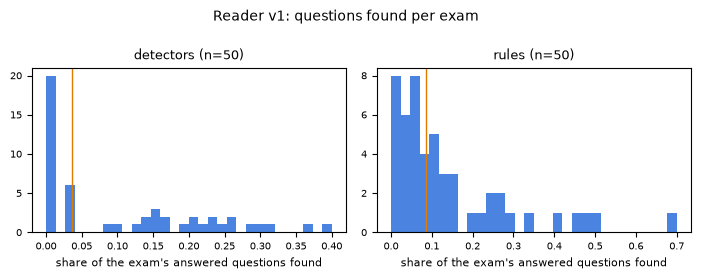

figure: found_per_exam_v1.png

Found, by question type:


type,mcq,written
mode,,
detectors,0.057,0.202
rules,0.193,0.037


In [3]:
questions = pd.read_csv(OUT / "reader_eval_questions_v1_all50.csv")
answered = questions[questions["answered"]]
per_exam = answered.groupby(["mode", "exam"])["found"].mean().unstack("mode")
eda.show(per_exam.describe().T[["mean", "min", "50%", "max"]], "Share of answered questions found, per exam:")
eda.histograms({mode: per_exam[mode] for mode in per_exam}, "share of the exam's answered questions found",
               OUT / "found_per_exam_v1.png", "Reader v1: questions found per exam")
eda.show(answered.groupby(["mode", "type"])["found"].mean().unstack("type"), "Found, by question type:")

**The detectors do not transfer.** The question-number detector, AP50 0.79 on its own test booklet, finds 11% of
the questions on the Mendeley exams; the median exam has 4% of its questions found and the best one 40%, so it
is the detector, not a few bad scans. Its highest confidence on any Mendeley page was 0.006, far below the
reader's threshold of 0.25. Every training booklet came from one source, with one way of writing and placing a
question number; the Mendeley exams are another exam, another layout and other writers.

## Part 2. Is there public data to retrain it on?

The fix for a detector that has seen one source is more sources. A search (try 5) looked for public datasets
with handwritten question numbers labelled: Roboflow Universe (the Gazi University question boxes and four
others), Hugging Face, IEEE DataPort and Kaggle.

In [4]:
eda.show(tries.set_index("step").loc[[5, 9], ["try", "result", "decision"]], "Tries 5 and 9:")


Tries 5 and 9:


,try,result,decision
step,,,
5,Search for public datasets with handwritten question numbers (Roboflow Universe: Gazi University question boxes and ...,"none usable: the Gazi set is printed Turkish test books; the others label whole regions, bubbles or nothing",no new training data for question numbers
9,Fine-tuning Qwen3-VL on the Roboflow answer sheets,the set has boxes but no transcriptions and comes from one source (the source the question_no detector overfitted to),not done


**None was usable**: the Gazi set is printed Turkish test books, and the others label whole regions, bubbles,
or nothing at all. Fine-tuning a reader on the step 1 answer sheets (try 9) was not run either: they have boxes
but no transcriptions, and come from the same single source the detector over-fitted to.

So the question number has to be found another way: **read it from the text**, as a person does. A line that
opens with "21." starts question 21. That only needs a reader good enough to read the number.

## Part 3. A mistake, and how it was corrected

The next tries (6 to 8) did that: the line detector finds the lines, a reader reads them, and the number is
taken from the start of the text. To see which reader and which rules worked, they were tried on 11 of the
Mendeley exams, with the other 39 held out. That broke the rule the project later set itself: **the Mendeley
exams are for evaluation only**. A choice made by looking at them makes their score optimistic, even on the
held-out 39, because every rule was shaped by what the same students wrote.

In [5]:
eda.show(tries.set_index("step").loc[[6, 7, 8], ["try", "result", "decision", "uses_mendeley"]],
         "Tries 6 to 8 (superseded):")
superseded = pd.read_csv(OUT / "superseded_mendeley_dev_reads.csv")
eda.show(superseded.groupby("try").agg(exams=("exam", "nunique"), numbers_read=("number", "count"),
                                       median_confidence=("confidence", "median")),
         "What each superseded try read on the 11 exams (numbers only; the text stays off the repo):")


Tries 6 to 8 (superseded):


,try,result,decision,uses_mendeley
step,,,,
6,"ocr mode, versions 1 to 4: line detector + TrOCR base, question number read from the start of the text, with sequenc...","questions found on the 11: v1 13.5%, v2 20.7%, widen+cut 15.3%, cut only 25.6%; on the 39: 31.1%, MCQ letters right ...",superseded: every rule was re-decided on the development set (steps 11 to 14),yes (not a clean evaluation)
7,"Readers compared: TrOCR base, TrOCR large, Qwen3-VL-2B on the line crops, Qwen3-VL-2B on the whole page","questions found: 25.6%, 34.3%, 46.1%, 90.8%; the page reader invented about 40 numbers per exam on blank pages and a...",superseded by the same comparison on the development set (step 11),yes (not a clean evaluation)
8,"Page reader safeguards tried on Mendeley: blank-page skip at 0.2% dark pixels, number-run filters, a line cap from t...","line cap: invented numbers 16.5 -> 0.7 per exam but questions found 90% -> 76%; loop filter of 12: 87% found, 0.8 in...",superseded and removed: the 0.2% threshold would have skipped real light-pen pages of the development set,yes (not a clean evaluation)



What each superseded try read on the 11 exams (numbers only; the text stays off the repo):


,exams,numbers_read,median_confidence
try,,,
qwen3-vl-2b lines (ocr mode),11,195,0.677
"qwen3-vl-2b page, greedy, blank skip + number filter",11,534,1.000
"qwen3-vl-2b page, greedy, line cap from detector",11,305,0.962
"qwen3-vl-2b page, greedy, no filter",11,934,1.000
trocr-large lines (ocr mode),11,144,0.316


They did show something worth keeping as a *hypothesis*: a vision-language model reading the **whole page**
(Qwen3-VL-2B) found far more question numbers than any reader on single lines (91% against 26 to 46%), but it
also invented numbers on blank pages and after the last answer. Those results cannot be used to choose, so
every choice is made again, on other data, in step 4. The three tries are marked `uses_mendeley = yes (not a
clean evaluation)` in `tries.csv` and are not reported as results.

## Conclusion, and why it leads to step 3

Two decisions come out of this chapter:

1. **The Mendeley exams are evaluation-only.** From here on, no reader, rule or threshold is chosen by looking at
   them. They are read once, at the end, by the frozen reader (step 7).
2. **Every design choice needs other data: a development set.** No public dataset has what Mendeley has (whole
   exam pages with numbered answers and a key), so step 3 puts one together from public handwriting, each part
   chosen for one thing the reader must do: read the text, find the numbers, and not invent anything.